In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    SplineTransformer,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 250)


def locate_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]

    for candidate in candidates:
        if (
            (candidate / "Data and Resources" / "respondent_scores.csv").exists()
            and (candidate / "Data and Resources" / "final_data.csv").exists()
        ):
            return candidate

    fallback = Path(
        "/Users/albert/Library/CloudStorage/"
        "OneDrive-andrew.cmu.edu/Documents/"
        "CMU 26-27/Undergraduate Research/Victimization/"
        "Code/capstone_victimization"
    )

    if fallback.exists():
        return fallback

    raise FileNotFoundError(
        "Could not locate the capstone_victimization project."
    )


PROJECT_ROOT = locate_project_root()
DATA_DIR = PROJECT_ROOT / "Data and Resources"
OUTPUT_DIR = PROJECT_ROOT / "Causal Inference" / "model_outputs"

ID_COL = "respondent_id"

MODEL_TYPES = [
    "logistic",
    "lasso",
    "gam",
    "random_forest",
    "xgboost",
]

# ============================================================
# CHANGE ONLY THIS LINE TO SWITCH MODELS
# ============================================================

ACTIVE_MODEL = "xgboost"

assert ACTIVE_MODEL in MODEL_TYPES

SAVE_OUTPUTS = True
N_PERMUTATIONS = 10

print(f"Project root: {PROJECT_ROOT}")
print(f"Active pseudo-outcome model: {ACTIVE_MODEL}")

Project root: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization
Active pseudo-outcome model: xgboost


In [28]:
numeric_features = [
    "total_number_of_incarcerations",
    "days_r_absent_from_school",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "household_net_worth",
    "household_size",
    "asvab_math_verbal_score_percent",
]

ordinal_features = [
    "teachers_good",
    "discipline_is_fair_agree_disagree",
    "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month",
    "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex",
    "biological_father_education",
    "biological_mother_education",
]

categorical_features = [
    "bullying_victim_before_age_12",
    "r_victim_of_bullying_12_18_years",
    "earliest_arrest_before_18",
    "sex",
    "r_ever_live_through_hard_times",
    "race_ethnicity",
    "mother_serve_prison_sentence",
    "father_serve_prison_sentence",
]

all_categorical_features = (
    ordinal_features + categorical_features
)

all_features = (
    numeric_features + all_categorical_features
)


# ============================================================
# LOAD FILES
# ============================================================

scores = pd.read_csv(
    DATA_DIR / "respondent_scores.csv"
)

reported_results = pd.read_csv(
    DATA_DIR / "results.csv"
)

covariate_data = pd.read_csv(
    DATA_DIR / "final_data.csv"
)

# Convert negative NLSY missing codes to NaN.
numeric_columns = (
    covariate_data
    .select_dtypes(include="number")
    .columns
    .difference([ID_COL])
)

covariate_data[numeric_columns] = (
    covariate_data[numeric_columns]
    .mask(
        covariate_data[numeric_columns] < 0
    )
)


# ============================================================
# VALIDATE SCORE FILE
# ============================================================

required_score_columns = [
    ID_COL,
    "model",
    "Z",
    "R",
    "mu1_minus_mu0",
    "phi_i",
]

missing_score_columns = [
    column
    for column in required_score_columns
    if column not in scores.columns
]

assert not missing_score_columns, (
    f"Missing score columns: {missing_score_columns}"
)

assert scores[
    [ID_COL, "model"]
].duplicated().sum() == 0

assert set(scores["model"].unique()) == set(
    MODEL_TYPES
)


# ============================================================
# CREATE ONE DATAFRAME PER MODEL
# ============================================================

model_datasets = {}

for model_name in MODEL_TYPES:
    model_scores = (
        scores.loc[
            scores["model"] == model_name
        ]
        .copy()
        .reset_index(drop=True)
    )

    assert model_scores[ID_COL].is_unique
    assert model_scores["phi_i"].notna().all()

    model_data = model_scores.merge(
        covariate_data[
            [ID_COL] + all_features
        ],
        on=ID_COL,
        how="left",
        validate="one_to_one",
    )

    assert len(model_data) == len(model_scores)

    # Standard name used by the remaining CATE code.
    model_data["dr_primary"] = (
        model_data["phi_i"]
    )

    model_datasets[model_name] = model_data


# Explicit dataframe names for convenient inspection.
df_logistic = model_datasets["logistic"]
df_lasso = model_datasets["lasso"]
df_gam = model_datasets["gam"]
df_random_forest = model_datasets[
    "random_forest"
]
df_xgboost = model_datasets["xgboost"]


# ============================================================
# SELECT ACTIVE DATASET
# ============================================================

analysis = model_datasets[
    ACTIVE_MODEL
].copy()

OVERALL_ATE = analysis[
    "dr_primary"
].mean()

print("Available model datasets:")

for model_name, model_data in model_datasets.items():
    print(
        f"  {model_name}: "
        f"{len(model_data):,} respondents"
    )

print(
    f"\nActive dataset: {ACTIVE_MODEL}"
)

print(
    f"ATE from mean phi_i: "
    f"{100 * OVERALL_ATE:.3f} percentage points"
)


# ============================================================
# VERIFY AGAINST RESULTS.CSV
# ============================================================

reported_row = reported_results.loc[
    (
        reported_results["model"]
        == ACTIVE_MODEL
    )
    & (
        reported_results["method"]
        == "Doubly robust"
    )
].squeeze()

assert not reported_row.empty

reported_ate_pp = float(
    reported_row["ATE (pp)"]
)

calculated_ate_pp = float(
    100 * OVERALL_ATE
)

assert np.isclose(
    calculated_ate_pp,
    reported_ate_pp,
    atol=1e-8,
)

print(
    f"Reported DR ATE: "
    f"{reported_ate_pp:.3f} percentage points"
)

print("ATE validation passed.")

print("\nTreatment counts:")
display(
    analysis["Z"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("n")
)

print("\nOutcome-observation indicator counts:")
display(
    analysis["R"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("n")
)

Available model datasets:
  logistic: 8,884 respondents
  lasso: 8,884 respondents
  gam: 8,884 respondents
  random_forest: 8,884 respondents
  xgboost: 8,884 respondents

Active dataset: xgboost
ATE from mean phi_i: -0.624 percentage points
Reported DR ATE: -0.624 percentage points
ATE validation passed.

Treatment counts:


,n
Z,
0,4238
1,4646



Outcome-observation indicator counts:


,n
R,
0,417
1,8467


In [29]:
quality_rows = []

for variable in all_features:
    observed = analysis[variable].dropna()

    row = {
        "variable": variable,
        "analysis_type": (
            "numeric"
            if variable in numeric_features
            else (
                "ordinal"
                if variable in ordinal_features
                else "categorical"
            )
        ),
        "n_observed": len(observed),
        "missing_percent": (
            100
            * analysis[variable]
            .isna()
            .mean()
        ),
        "unique_values": (
            observed.nunique()
        ),
    }

    if variable in numeric_features:
        row["zero_percent_observed"] = (
            100
            * (observed == 0).mean()
        )
    else:
        row["zero_percent_observed"] = np.nan

    quality_rows.append(row)

variable_quality = pd.DataFrame(
    quality_rows
)

display(
    variable_quality.round(1)
)

,variable,analysis_type,n_observed,missing_percent,unique_values,zero_percent_observed
0,total_number_of_incarcerations,numeric,8849,0.4,11,89.0
1,days_r_absent_from_school,numeric,8590,3.3,60,19.3
2,r_threatened_to_be_hurt_at_school,numeric,8771,1.3,30,79.1
3,r_in_a_fight_at_school,numeric,8774,1.2,23,82.4
4,household_net_worth,numeric,6144,30.8,2298,0.0
5,household_size,numeric,8884,0.0,16,0.0
6,asvab_math_verbal_score_percent,numeric,7055,20.6,6783,0.3
7,teachers_good,ordinal,8867,0.2,4,NaN
8,discipline_is_fair_agree_disagree,ordinal,8845,0.4,4,NaN
9,percent_of_peers_who_smoke,ordinal,8774,1.2,5,NaN


In [30]:
def fit_second_stage(
    X,
    valid_mask,
    model,
):
    """
    Fit and evaluate a second-stage model on the same data.

    These metrics are apparent/in-sample and should not be
    interpreted as estimates of generalization performance.
    """
    valid_mask = np.asarray(
        valid_mask,
        dtype=bool,
    )

    target = analysis[
        "dr_primary"
    ].to_numpy(dtype=float)

    model.fit(
        X.loc[valid_mask],
        target[valid_mask],
    )

    prediction = np.full(
        len(analysis),
        np.nan,
    )

    prediction[valid_mask] = model.predict(
        X.loc[valid_mask]
    )

    baseline_value = target[
        valid_mask
    ].mean()

    baseline_prediction = np.repeat(
        baseline_value,
        valid_mask.sum(),
    )

    model_mse = mean_squared_error(
        target[valid_mask],
        prediction[valid_mask],
    )

    baseline_mse = mean_squared_error(
        target[valid_mask],
        baseline_prediction,
    )

    apparent_pseudo_r2 = (
        1 - model_mse / baseline_mse
    )

    return {
        "mean_prediction": prediction,
        "fitted_model": model,
        "model_MSE": model_mse,
        "baseline_MSE": baseline_mse,
        "apparent_pseudo_R2": apparent_pseudo_r2,
    }


def make_numeric_linear_model():
    return Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "scale",
            StandardScaler(),
        ),
        (
            "regression",
            LinearRegression(),
        ),
    ])


def make_numeric_spline_model():
    return Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=5,
                degree=3,
                knots="quantile",
                include_bias=False,
            ),
        ),
        (
            "scale",
            StandardScaler(),
        ),
        (
            "regression",
            Ridge(alpha=1.0),
        ),
    ])


def make_factor_model():
    return Pipeline([
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=20,
                drop="first",
            ),
        ),
        (
            "regression",
            LinearRegression(),
        ),
    ])

In [31]:
numeric_results = {}
numeric_comparison_rows = []

for variable in numeric_features:
    print(f"Fitting: {variable}")

    X_variable = analysis[
        [variable]
    ].copy()

    valid_mask = analysis[
        variable
    ].notna().to_numpy()

    linear_result = fit_second_stage(
        X=X_variable,
        valid_mask=valid_mask,
        model=make_numeric_linear_model(),
    )

    spline_result = fit_second_stage(
        X=X_variable,
        valid_mask=valid_mask,
        model=make_numeric_spline_model(),
    )

    numeric_results[variable] = {
        "linear": linear_result,
        "spline": spline_result,
    }

    observed = analysis.loc[
        valid_mask,
        variable,
    ]

    numeric_comparison_rows.append({
        "variable": variable,
        "n_observed": valid_mask.sum(),
        "missing_percent": (
            100 * (~valid_mask).mean()
        ),
        "unique_values": observed.nunique(),
        "zero_percent": (
            100 * (observed == 0).mean()
        ),
        "baseline_MSE": linear_result[
            "baseline_MSE"
        ],
        "linear_MSE": linear_result[
            "model_MSE"
        ],
        "linear_apparent_pseudo_R2": (
            linear_result[
                "apparent_pseudo_R2"
            ]
        ),
        "spline_MSE": spline_result[
            "model_MSE"
        ],
        "spline_apparent_pseudo_R2": (
            spline_result[
                "apparent_pseudo_R2"
            ]
        ),
    })

numeric_model_comparison = (
    pd.DataFrame(
        numeric_comparison_rows
    )
    .sort_values(
        "spline_apparent_pseudo_R2",
        ascending=False,
    )
)

display(
    numeric_model_comparison.round(6)
)

print(
    "These pseudo-R² values are apparent/in-sample."
)

Fitting: total_number_of_incarcerations
Fitting: days_r_absent_from_school
Fitting: r_threatened_to_be_hurt_at_school
Fitting: r_in_a_fight_at_school
Fitting: household_net_worth
Fitting: household_size
Fitting: asvab_math_verbal_score_percent


,variable,n_observed,missing_percent,unique_values,zero_percent,baseline_MSE,linear_MSE,linear_apparent_pseudo_R2,spline_MSE,spline_apparent_pseudo_R2
6,asvab_math_verbal_score_percent,7055,20.587573,6783,0.269313,0.461328,0.461308,0.000043,0.460739,0.001276
4,household_net_worth,6144,30.841963,2298,0.048828,0.461001,0.460744,0.000557,0.460668,0.000723
5,household_size,8884,0.000000,16,0.000000,0.420331,0.420136,0.000464,0.420056,0.000654
1,days_r_absent_from_school,8590,3.309320,60,19.289872,0.402181,0.402173,0.000020,0.401986,0.000484
0,total_number_of_incarcerations,8849,0.393967,11,88.970505,0.421533,0.421508,0.000059,0.421429,0.000246
2,r_threatened_to_be_hurt_at_school,8771,1.271950,30,79.090184,0.403406,0.403405,0.000002,0.403346,0.000149
3,r_in_a_fight_at_school,8774,1.238181,23,82.402553,0.403285,0.403273,0.000030,0.403254,0.000076


These pseudo-R² values are apparent/in-sample.


total_number_of_incarcerations
Apparent linear pseudo-R²: 0.00006
Apparent spline pseudo-R²: 0.00025
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 1,008 of 8,849 (11.4%)


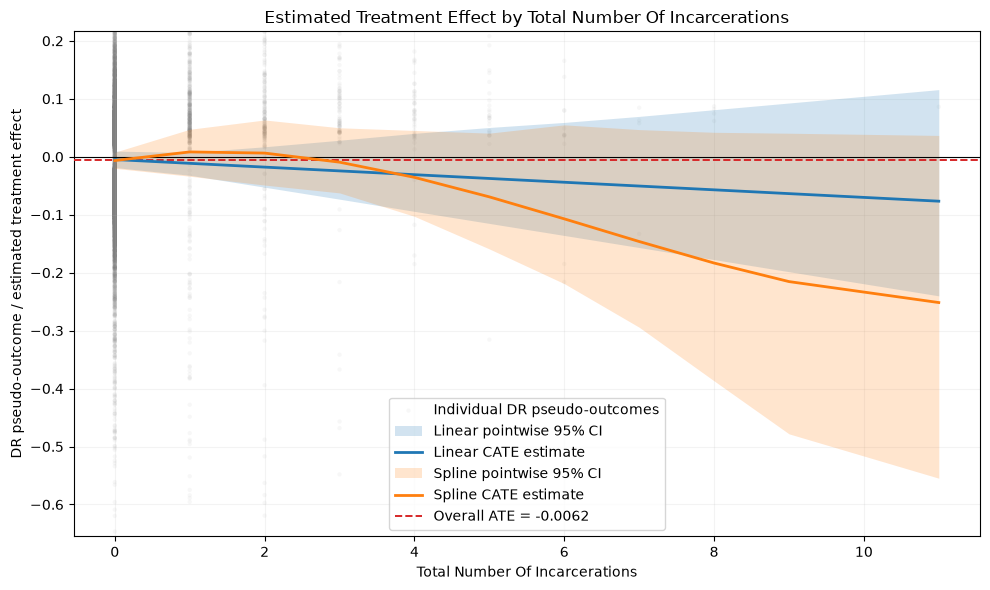

days_r_absent_from_school
Apparent linear pseudo-R²: 0.00002
Apparent spline pseudo-R²: 0.00048
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 568 of 8,590 (6.6%)


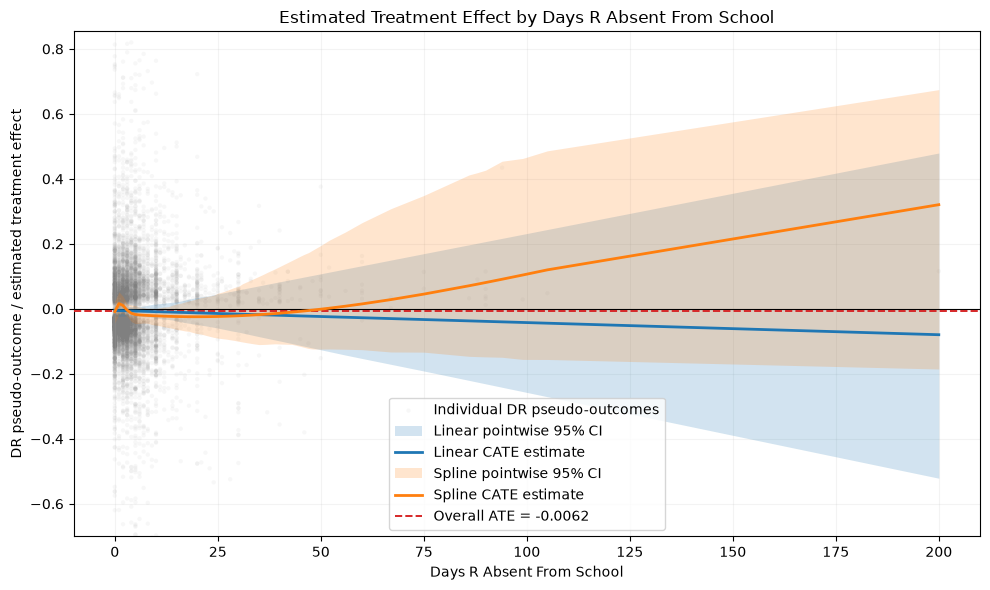

r_threatened_to_be_hurt_at_school
Apparent linear pseudo-R²: 0.00000
Apparent spline pseudo-R²: 0.00015
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 991 of 8,771 (11.3%)


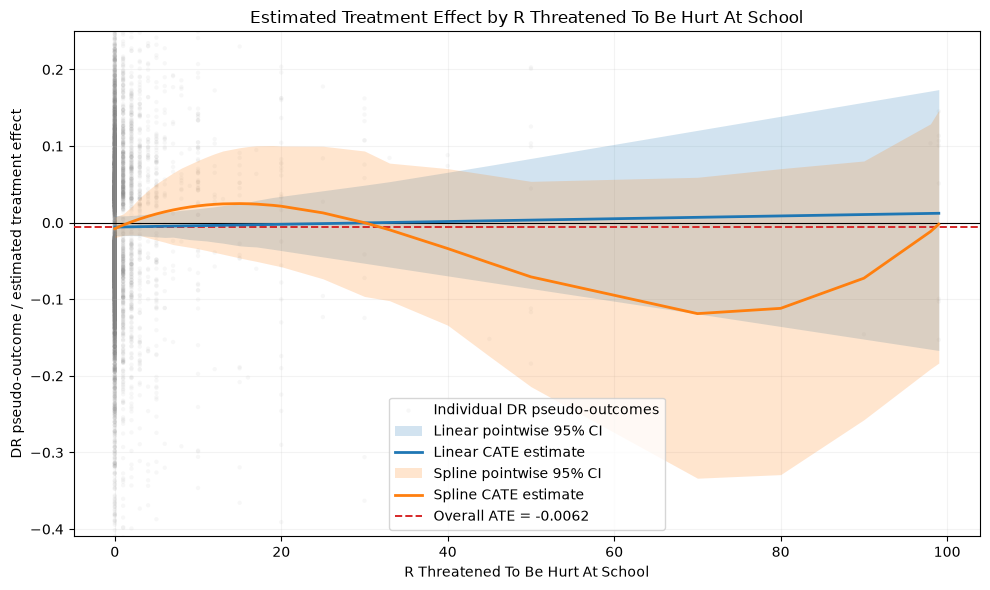

r_in_a_fight_at_school
Apparent linear pseudo-R²: 0.00003
Apparent spline pseudo-R²: 0.00008
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 797 of 8,774 (9.1%)


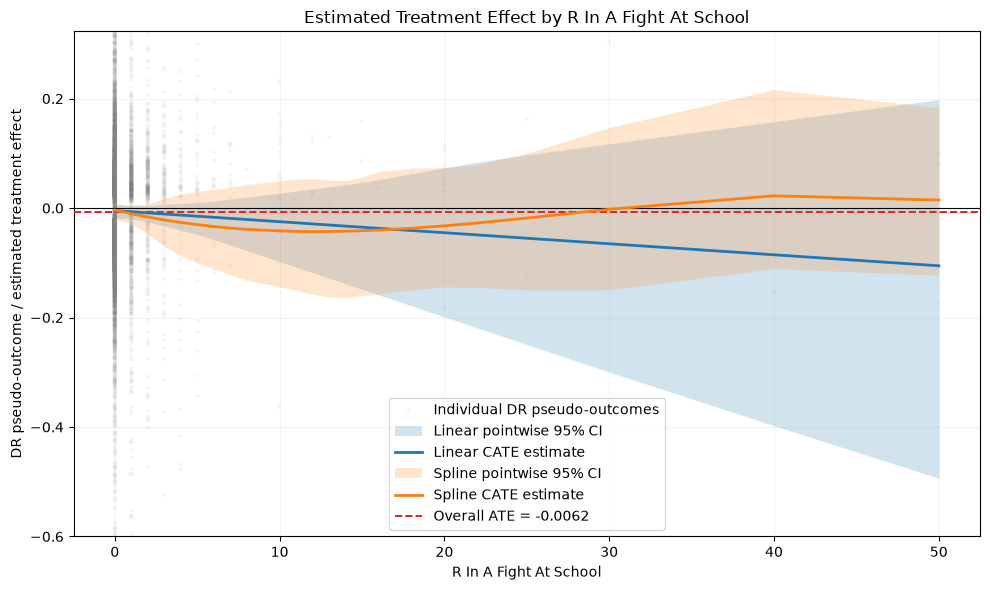

household_net_worth
Apparent linear pseudo-R²: 0.00056
Apparent spline pseudo-R²: 0.00072
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 1,379 of 6,144 (22.4%)


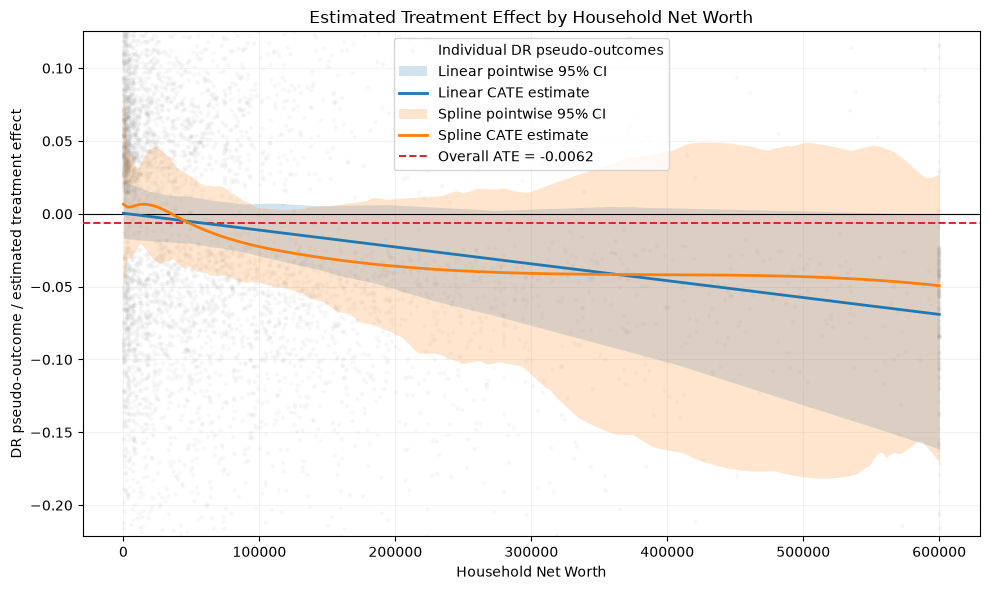

household_size
Apparent linear pseudo-R²: 0.00046
Apparent spline pseudo-R²: 0.00065
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 770 of 8,884 (8.7%)


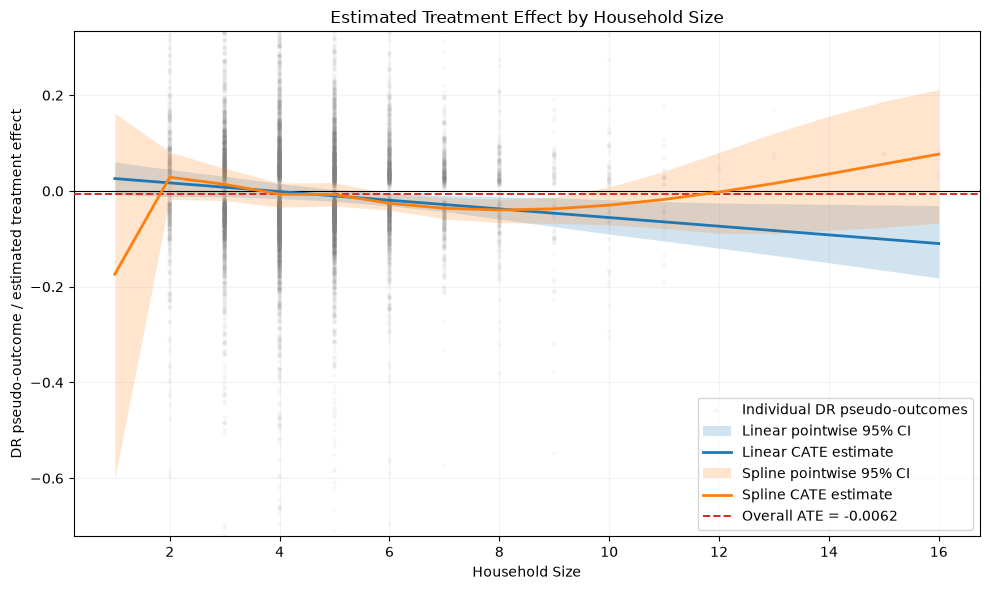

asvab_math_verbal_score_percent
Apparent linear pseudo-R²: 0.00004
Apparent spline pseudo-R²: 0.00128
Plot y-axis is zoomed to the fitted CATE curves and confidence bands.
Pseudo-outcome points outside displayed range: 1,294 of 7,055 (18.3%)


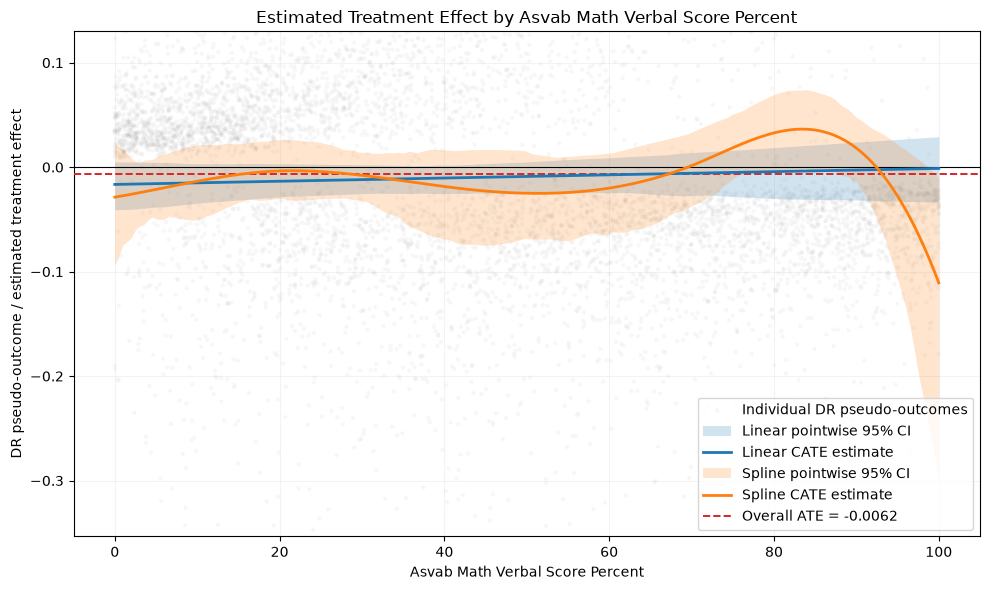

In [40]:
# ============================================================
# INDIVIDUAL SCATTERPLOTS WITH BOOTSTRAP CATE BANDS
# ============================================================

N_BOOTSTRAPS = 200
CONFIDENCE_LEVEL = 0.95


def numeric_cate_curves_with_ci(
    variable,
    n_bootstraps=N_BOOTSTRAPS,
    confidence_level=CONFIDENCE_LEVEL,
):
    valid = analysis[variable].notna()

    X_observed = (
        analysis.loc[valid, [variable]]
        .reset_index(drop=True)
    )

    y_observed = (
        analysis.loc[valid, "dr_primary"]
        .to_numpy(dtype=float)
    )

    x_observed = (
        X_observed[variable]
        .to_numpy(dtype=float)
    )

    unique_x = np.sort(
        np.unique(x_observed)
    )

    # For discrete/count variables, predict only at observed
    # values. For highly continuous variables, use a smooth grid.
    if len(unique_x) <= 200:
        x_grid = unique_x
    else:
        x_grid = np.linspace(
            x_observed.min(),
            x_observed.max(),
            200,
        )

    X_grid = pd.DataFrame({
        variable: x_grid
    })

    # Curves from the models fitted to the complete observed sample.
    fitted_linear_model = (
        numeric_results[variable][
            "linear"
        ]["fitted_model"]
    )

    fitted_spline_model = (
        numeric_results[variable][
            "spline"
        ]["fitted_model"]
    )

    linear_estimate = (
        fitted_linear_model.predict(
            X_grid
        )
    )

    spline_estimate = (
        fitted_spline_model.predict(
            X_grid
        )
    )

    # Store predictions from each bootstrap refit.
    linear_bootstrap_predictions = np.empty(
        (n_bootstraps, len(x_grid))
    )

    spline_bootstrap_predictions = np.empty(
        (n_bootstraps, len(x_grid))
    )

    # Reproducible but distinct seed for each variable.
    variable_seed = (
        2026
        + sum(
            (position + 1) * ord(character)
            for position, character
            in enumerate(variable)
        )
    )

    rng = np.random.default_rng(
        variable_seed
    )

    n_observed = len(X_observed)

    for bootstrap_number in range(
        n_bootstraps
    ):
        bootstrap_indices = rng.integers(
            low=0,
            high=n_observed,
            size=n_observed,
        )

        X_bootstrap = (
            X_observed
            .iloc[bootstrap_indices]
            .reset_index(drop=True)
        )

        y_bootstrap = y_observed[
            bootstrap_indices
        ]

        bootstrap_linear_model = (
            make_numeric_linear_model()
        )

        bootstrap_spline_model = (
            make_numeric_spline_model()
        )

        bootstrap_linear_model.fit(
            X_bootstrap,
            y_bootstrap,
        )

        bootstrap_spline_model.fit(
            X_bootstrap,
            y_bootstrap,
        )

        linear_bootstrap_predictions[
            bootstrap_number
        ] = bootstrap_linear_model.predict(
            X_grid
        )

        spline_bootstrap_predictions[
            bootstrap_number
        ] = bootstrap_spline_model.predict(
            X_grid
        )

    lower_percentile = (
        100 * (1 - confidence_level) / 2
    )

    upper_percentile = (
        100 - lower_percentile
    )

    linear_lower = np.percentile(
        linear_bootstrap_predictions,
        lower_percentile,
        axis=0,
    )

    linear_upper = np.percentile(
        linear_bootstrap_predictions,
        upper_percentile,
        axis=0,
    )

    spline_lower = np.percentile(
        spline_bootstrap_predictions,
        lower_percentile,
        axis=0,
    )

    spline_upper = np.percentile(
        spline_bootstrap_predictions,
        upper_percentile,
        axis=0,
    )

    return {
        "x_observed": x_observed,
        "y_observed": y_observed,
        "x_grid": x_grid,
        "linear_estimate": linear_estimate,
        "linear_lower": linear_lower,
        "linear_upper": linear_upper,
        "spline_estimate": spline_estimate,
        "spline_lower": spline_lower,
        "spline_upper": spline_upper,
    }


def plot_numeric_cate(variable):
    results = numeric_cate_curves_with_ci(
        variable
    )

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    # Individual DR pseudo-outcomes.
    ax.scatter(
        results["x_observed"],
        results["y_observed"],
        s=10,
        alpha=0.06,
        color="gray",
        edgecolors="none",
        rasterized=True,
        label="Individual DR pseudo-outcomes",
        zorder=1,
    )

    # Linear confidence band and fitted curve.
    ax.fill_between(
        results["x_grid"],
        results["linear_lower"],
        results["linear_upper"],
        color="tab:blue",
        alpha=0.20,
        linewidth=0,
        label="Linear pointwise 95% CI",
        zorder=2,
    )

    ax.plot(
        results["x_grid"],
        results["linear_estimate"],
        color="tab:blue",
        linewidth=2,
        label="Linear CATE estimate",
        zorder=4,
    )

    # Spline confidence band and fitted curve.
    ax.fill_between(
        results["x_grid"],
        results["spline_lower"],
        results["spline_upper"],
        color="tab:orange",
        alpha=0.20,
        linewidth=0,
        label="Spline pointwise 95% CI",
        zorder=2,
    )

    ax.plot(
        results["x_grid"],
        results["spline_estimate"],
        color="tab:orange",
        linewidth=2,
        label="Spline CATE estimate",
        zorder=4,
    )

    # Reference lines.
    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.axhline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.4,
        label=(
            f"Overall ATE = "
            f"{OVERALL_ATE:.4f}"
        ),
        zorder=3,
    )

        # ========================================================
    # ZOOM Y-AXIS AROUND CATE CURVES AND CONFIDENCE BANDS
    # ========================================================

    curve_values = np.concatenate([
        results["linear_estimate"],
        results["linear_lower"],
        results["linear_upper"],
        results["spline_estimate"],
        results["spline_lower"],
        results["spline_upper"],
        np.array([
            0,
            OVERALL_ATE,
        ]),
    ])

    curve_values = curve_values[
        np.isfinite(curve_values)
    ]

    y_lower = curve_values.min()
    y_upper = curve_values.max()

    y_range = y_upper - y_lower

    # Add space above and below the curves.
    # The minimum padding is 0.005, or 0.5 percentage points.
    y_padding = max(
        0.005,
        0.15 * y_range,
    )

    plot_y_lower = y_lower - y_padding
    plot_y_upper = y_upper + y_padding

    ax.set_ylim(
        plot_y_lower,
        plot_y_upper,
    )

    # Report how many pseudo-outcome points are outside
    # the displayed y-axis range.
    n_below = np.sum(
        results["y_observed"]
        < plot_y_lower
    )

    n_above = np.sum(
        results["y_observed"]
        > plot_y_upper
    )

    n_total = len(
        results["y_observed"]
    )

    print(
        "Plot y-axis is zoomed to the fitted "
        "CATE curves and confidence bands."
    )

    print(
        f"Pseudo-outcome points outside displayed range: "
        f"{n_below + n_above:,} of {n_total:,} "
        f"({100 * (n_below + n_above) / n_total:.1f}%)"
    )

    readable_name = (
        variable
        .replace("_", " ")
        .title()
    )

    ax.set_title(
        f"Estimated Treatment Effect by "
        f"{readable_name}"
    )

    ax.set_xlabel(readable_name)

    ax.set_ylabel(
        "DR pseudo-outcome / estimated treatment effect"
    )

    ax.legend()
    ax.grid(alpha=0.15)

    plt.tight_layout()
    plt.show()


for variable in numeric_features:
    row = numeric_model_comparison.loc[
        numeric_model_comparison[
            "variable"
        ] == variable
    ].iloc[0]

    print("=" * 80)
    print(variable)

    print(
        "Apparent linear pseudo-R²: "
        f"{row['linear_apparent_pseudo_R2']:.5f}"
    )

    print(
        "Apparent spline pseudo-R²: "
        f"{row['spline_apparent_pseudo_R2']:.5f}"
    )

    plot_numeric_cate(variable)

In [33]:
categorical_results = {}
categorical_comparison_rows = []

for variable in all_categorical_features:
    print(f"Fitting: {variable}")

    X_variable = (
        analysis[[variable]]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

    valid_mask = np.ones(
        len(analysis),
        dtype=bool,
    )

    result = fit_second_stage(
        X=X_variable,
        valid_mask=valid_mask,
        model=make_factor_model(),
    )

    categorical_results[
        variable
    ] = result

    counts = (
        X_variable[variable]
        .value_counts()
    )

    categorical_comparison_rows.append({
        "variable": variable,
        "n_levels": (
            X_variable[variable]
            .nunique()
        ),
        "smallest_level_n": counts.min(),
        "model_MSE": result[
            "model_MSE"
        ],
        "baseline_MSE": result[
            "baseline_MSE"
        ],
        "apparent_pseudo_R2": result[
            "apparent_pseudo_R2"
        ],
    })

categorical_model_comparison = (
    pd.DataFrame(
        categorical_comparison_rows
    )
    .sort_values(
        "apparent_pseudo_R2",
        ascending=False,
    )
)

display(
    categorical_model_comparison.round(6)
)

print(
    "These pseudo-R² values are apparent/in-sample."
)

Fitting: teachers_good
Fitting: discipline_is_fair_agree_disagree
Fitting: percent_of_peers_who_smoke
Fitting: percent_of_peers_who_get_drunk_1_times_a_month
Fitting: percent_of_peers_belong_to_a_gang
Fitting: percent_of_peers_who_have_had_sex
Fitting: biological_father_education
Fitting: biological_mother_education
Fitting: bullying_victim_before_age_12
Fitting: r_victim_of_bullying_12_18_years
Fitting: earliest_arrest_before_18
Fitting: sex
Fitting: r_ever_live_through_hard_times
Fitting: race_ethnicity
Fitting: mother_serve_prison_sentence
Fitting: father_serve_prison_sentence


,variable,n_levels,smallest_level_n,model_MSE,baseline_MSE,apparent_pseudo_R2
7,biological_mother_education,22,6,0.419126,0.420331,0.002867
6,biological_father_education,22,1,0.419634,0.420331,0.001658
0,teachers_good,5,17,0.419858,0.420331,0.001124
1,discipline_is_fair_agree_disagree,5,39,0.420005,0.420331,0.000774
14,mother_serve_prison_sentence,3,94,0.420052,0.420331,0.000664
2,percent_of_peers_who_smoke,6,110,0.420100,0.420331,0.000549
11,sex,2,4330,0.420145,0.420331,0.000442
13,race_ethnicity,5,156,0.420173,0.420331,0.000377
4,percent_of_peers_belong_to_a_gang,6,170,0.420200,0.420331,0.000311
5,percent_of_peers_who_have_had_sex,6,537,0.420223,0.420331,0.000256


These pseudo-R² values are apparent/in-sample.


teachers_good
Apparent factor-model pseudo-R²: 0.00112


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,1555,-0.01071,0.74962,-0.01071,0.01901,-0.04797,0.02655
1,2.0,6128,-0.00081,0.60136,-0.00081,0.00768,-0.01586,0.01425
2,3.0,950,-0.01986,0.64477,-0.01986,0.02092,-0.06086,0.02114
3,4.0,234,-0.02963,0.49728,-0.02963,0.03251,-0.09334,0.03409
4,Missing,17,-0.47165,3.43613,-0.47165,0.83339,-2.10508,1.16179


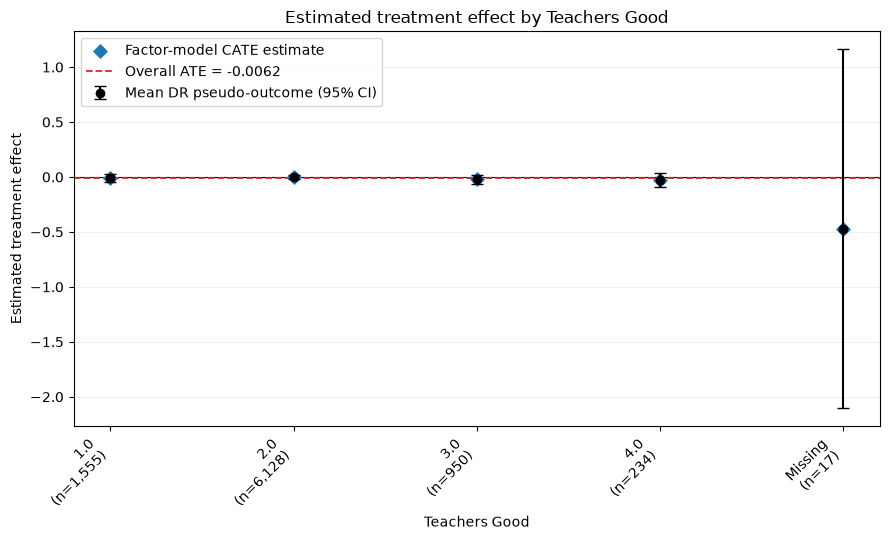

discipline_is_fair_agree_disagree
Apparent factor-model pseudo-R²: 0.00077


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,1457,-0.00126,0.62989,-0.00126,0.01650,-0.03360,0.03108
1,2.0,4874,-0.01320,0.59753,-0.01320,0.00856,-0.02998,0.00357
2,3.0,1925,0.01002,0.65925,0.01002,0.01503,-0.01943,0.03947
3,4.0,589,0.00121,0.80991,0.00121,0.03337,-0.06419,0.06662
4,Missing,39,-0.23700,2.24713,-0.23700,0.35983,-0.94227,0.46826


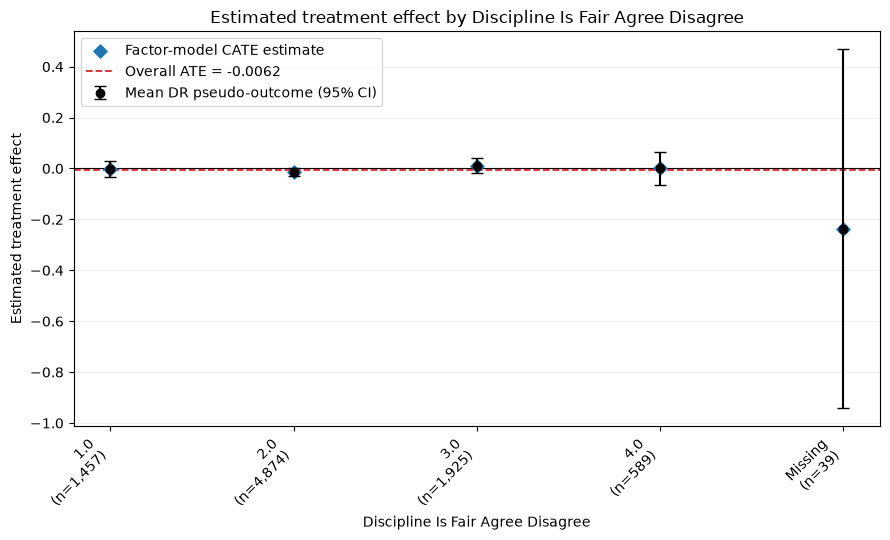

percent_of_peers_who_smoke
Apparent factor-model pseudo-R²: 0.00055


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,2297,-0.01457,0.62179,-0.01457,0.01297,-0.04000,0.01086
1,2.0,1949,-0.00569,0.64708,-0.00569,0.01466,-0.03442,0.02304
2,3.0,2146,-0.01952,0.74821,-0.01952,0.01615,-0.05118,0.01214
3,4.0,1636,0.02220,0.64807,0.02220,0.01602,-0.00920,0.05360
4,5.0,746,-0.00047,0.41838,-0.00047,0.01532,-0.03049,0.02955
5,Missing,110,-0.04494,0.31658,-0.04494,0.03018,-0.10410,0.01422


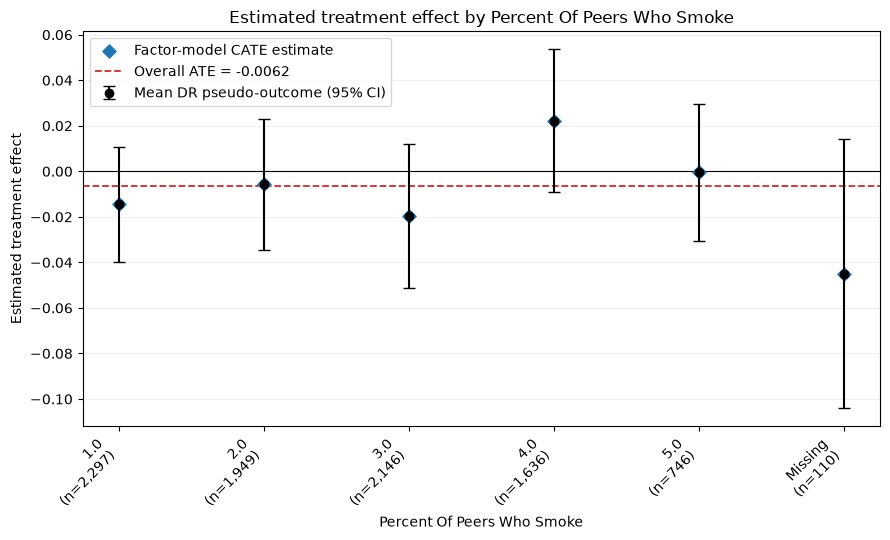

percent_of_peers_who_get_drunk_1_times_a_month
Apparent factor-model pseudo-R²: 0.00007


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,3801,-0.00542,0.61743,-0.00542,0.01001,-0.02505,0.01421
1,2.0,1870,-0.00366,0.70533,-0.00366,0.01631,-0.03563,0.02831
2,3.0,1555,-0.00930,0.69527,-0.00930,0.01763,-0.04386,0.02526
3,4.0,988,0.00174,0.71599,0.00174,0.02278,-0.04291,0.04638
4,5.0,488,-0.02133,0.37004,-0.02133,0.01675,-0.05416,0.01150
5,Missing,182,-0.02640,0.41791,-0.02640,0.03098,-0.08712,0.03431


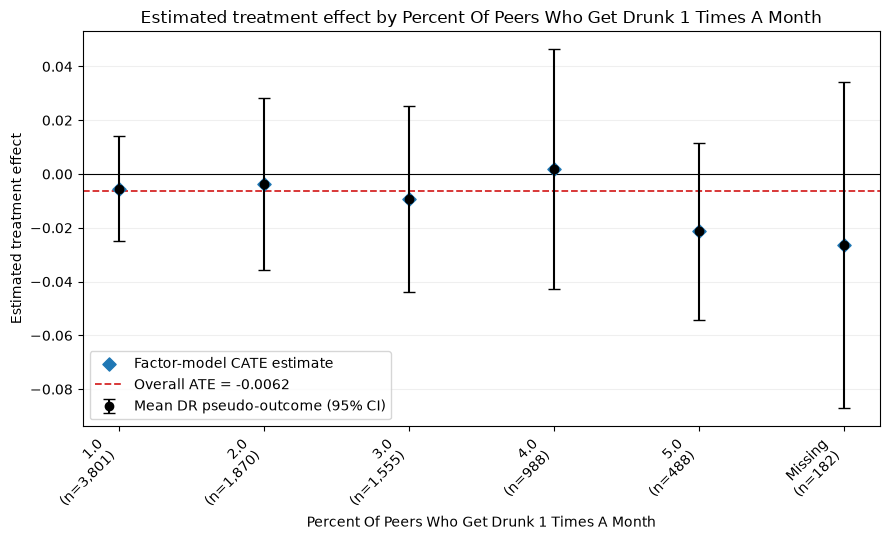

percent_of_peers_belong_to_a_gang
Apparent factor-model pseudo-R²: 0.00031


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,5620,-0.01151,0.65992,-0.01151,0.00880,-0.02876,0.00575
1,2.0,1809,0.01082,0.59100,0.01082,0.01390,-0.01642,0.03805
2,3.0,694,-0.02581,0.68471,-0.02581,0.02599,-0.07675,0.02513
3,4.0,363,0.01375,0.70801,0.01375,0.03716,-0.05909,0.08658
4,5.0,228,0.00423,0.70341,0.00423,0.04658,-0.08708,0.09553
5,Missing,170,0.00966,0.46036,0.00966,0.03531,-0.05954,0.07887


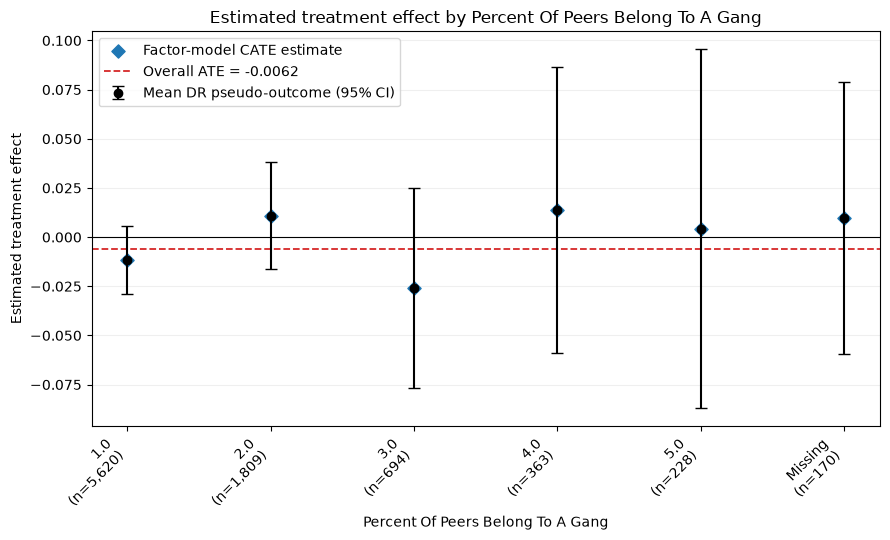

percent_of_peers_who_have_had_sex
Apparent factor-model pseudo-R²: 0.00026


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,689,0.00972,0.50257,0.00972,0.01915,-0.02781,0.04725
1,2.0,849,0.00032,0.77705,0.00032,0.02667,-0.05195,0.05259
2,3.0,1144,-0.00793,0.54455,-0.00793,0.01610,-0.03949,0.02363
3,4.0,707,0.01790,0.78112,0.01790,0.02938,-0.03968,0.07548
4,5.0,537,0.00364,0.42169,0.00364,0.01820,-0.03202,0.03931
5,Missing,4958,-0.01370,0.66353,-0.01370,0.00942,-0.03217,0.00477


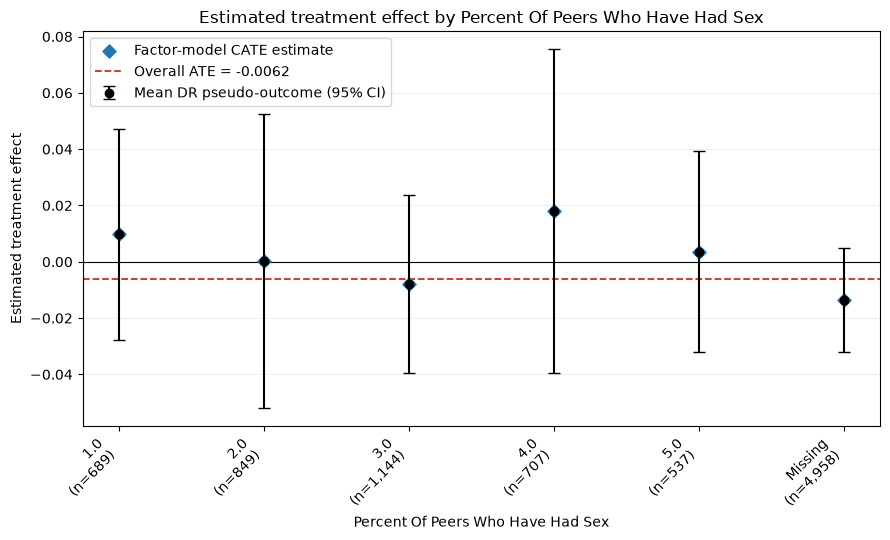

biological_father_education
Apparent factor-model pseudo-R²: 0.00166


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,1,-1.07184,NaN,-0.08052,NaN,NaN,NaN
1,2.0,19,-0.03555,0.35641,-0.08052,0.08177,-0.19581,0.12471
2,3.0,67,0.01892,0.73439,0.01892,0.08972,-0.15693,0.19477
3,4.0,59,-0.07361,0.34183,-0.07360,0.04450,-0.16083,0.01362
4,5.0,66,-0.05157,0.27698,-0.05159,0.03409,-0.11839,0.01525
5,6.0,186,-0.03042,0.37594,-0.03042,0.02757,-0.08445,0.02361
6,7.0,92,-0.12478,0.85370,-0.12478,0.08900,-0.29923,0.04967
7,8.0,168,-0.02896,0.57527,-0.02896,0.04438,-0.11595,0.05803
8,9.0,240,0.01055,0.62725,0.01055,0.04049,-0.06881,0.08990
9,10.0,320,-0.01538,0.41043,-0.01538,0.02294,-0.06035,0.02959


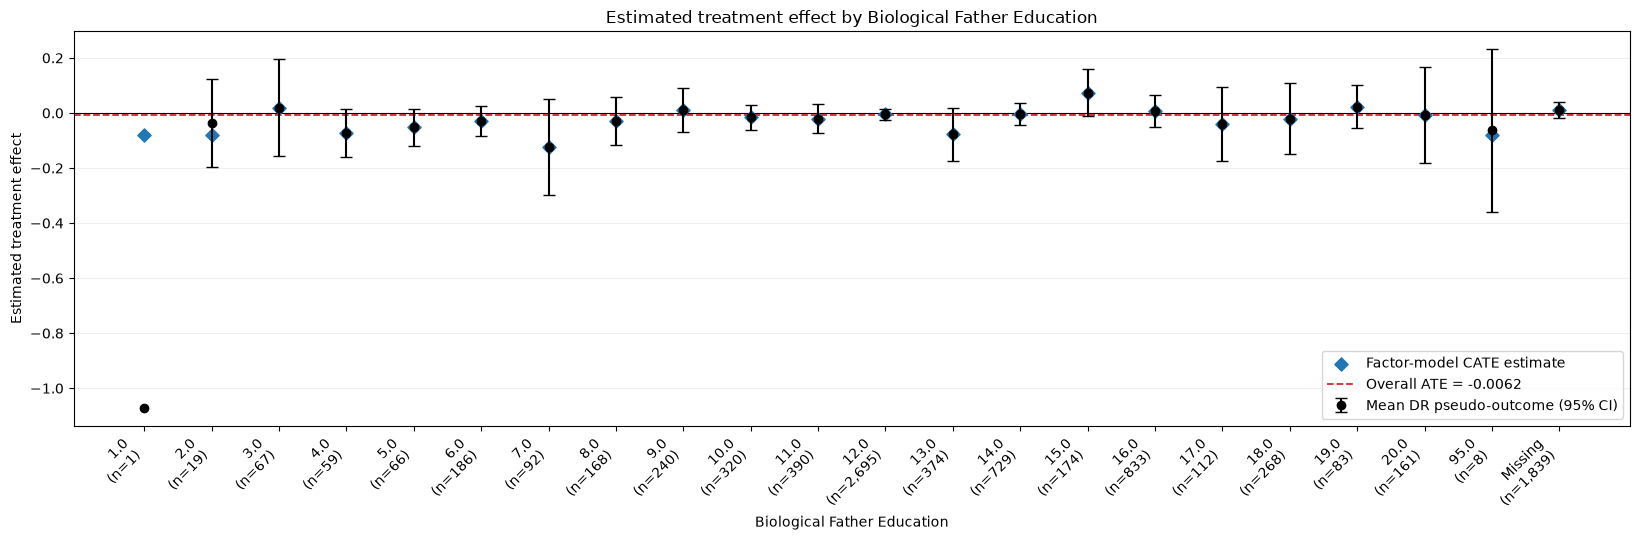

biological_mother_education
Apparent factor-model pseudo-R²: 0.00287


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1.0,6,0.01404,0.10080,-0.10870,0.04115,-0.06662,0.09470
1,2.0,29,-0.00603,0.09115,-0.00601,0.01693,-0.03920,0.02715
2,3.0,53,-0.10744,0.44628,-0.10744,0.06130,-0.22759,0.01271
3,4.0,52,-0.07730,0.40690,-0.07729,0.05643,-0.18789,0.03330
4,5.0,55,0.01425,0.13145,0.01425,0.01772,-0.02049,0.04899
5,6.0,219,-0.03083,0.70478,-0.03083,0.04762,-0.12418,0.06251
6,7.0,67,0.02437,0.26649,0.02438,0.03256,-0.03944,0.08818
7,8.0,204,0.01550,0.58524,0.01550,0.04098,-0.06481,0.09581
8,9.0,269,0.01863,0.35355,0.01863,0.02156,-0.02362,0.06088
9,10.0,426,-0.03026,0.51087,-0.03027,0.02475,-0.07877,0.01825


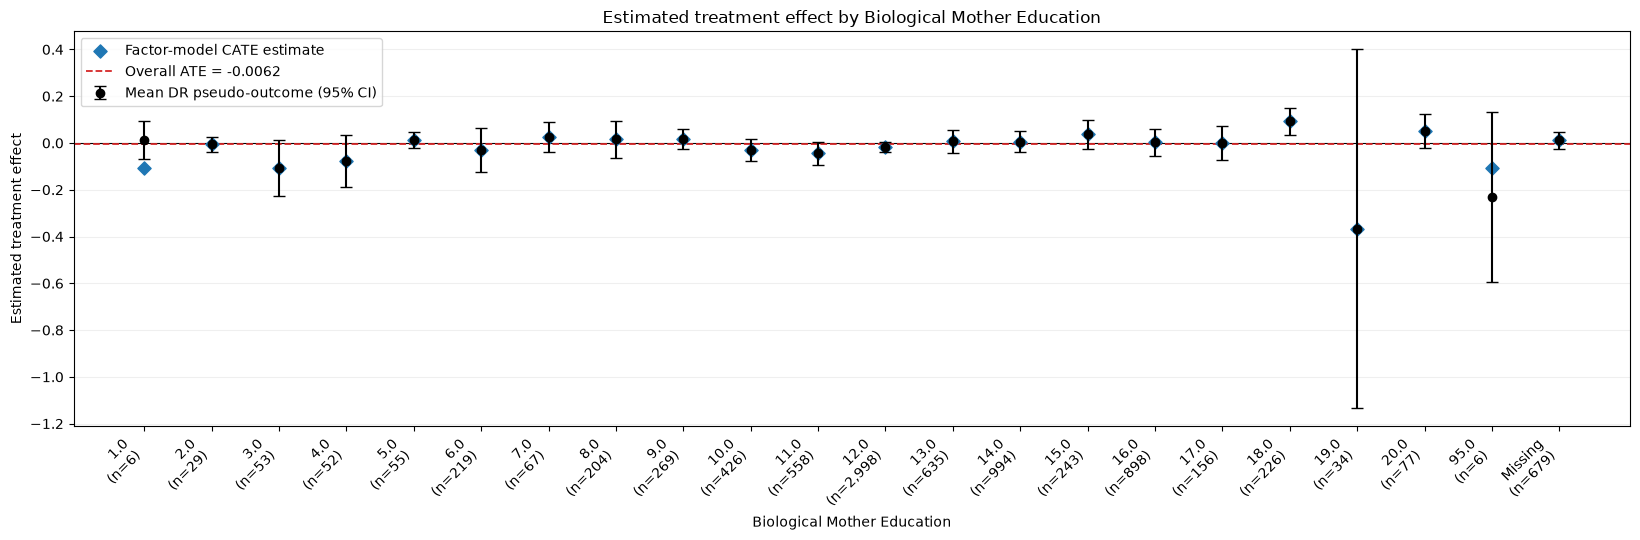

bullying_victim_before_age_12
Apparent factor-model pseudo-R²: 0.00011


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,0.0,7030,-0.00323,0.57444,-0.00323,0.00685,-0.01665,0.01020
1,1.0,1703,-0.01992,0.89887,-0.01992,0.02178,-0.06261,0.02277
2,Missing,151,0.00790,0.51154,0.00790,0.04163,-0.07370,0.08949


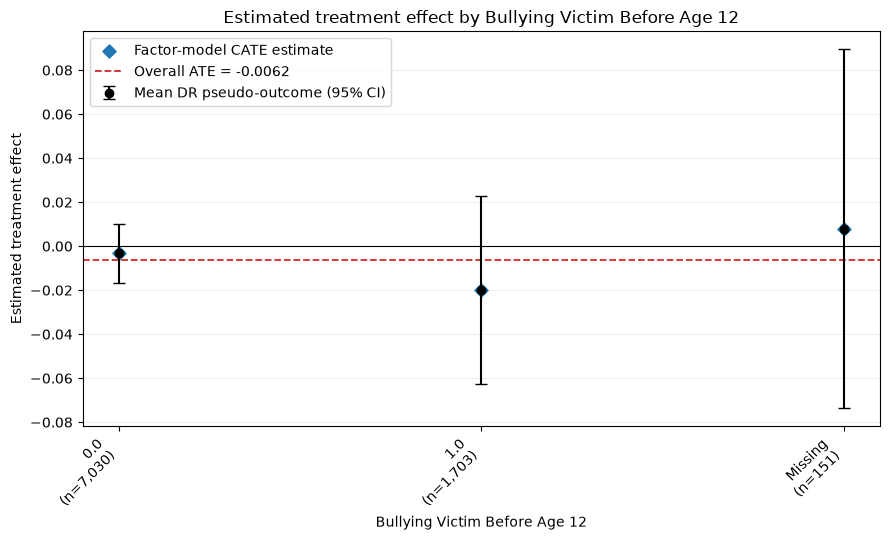

r_victim_of_bullying_12_18_years
Apparent factor-model pseudo-R²: 0.00004


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,0.0,6053,-0.00819,0.61317,-0.00819,0.00788,-0.02364,0.00726
1,1.0,899,0.00631,1.01154,0.00631,0.03374,-0.05982,0.07243
2,Missing,1932,-0.00596,0.52872,-0.00596,0.01203,-0.02954,0.01761


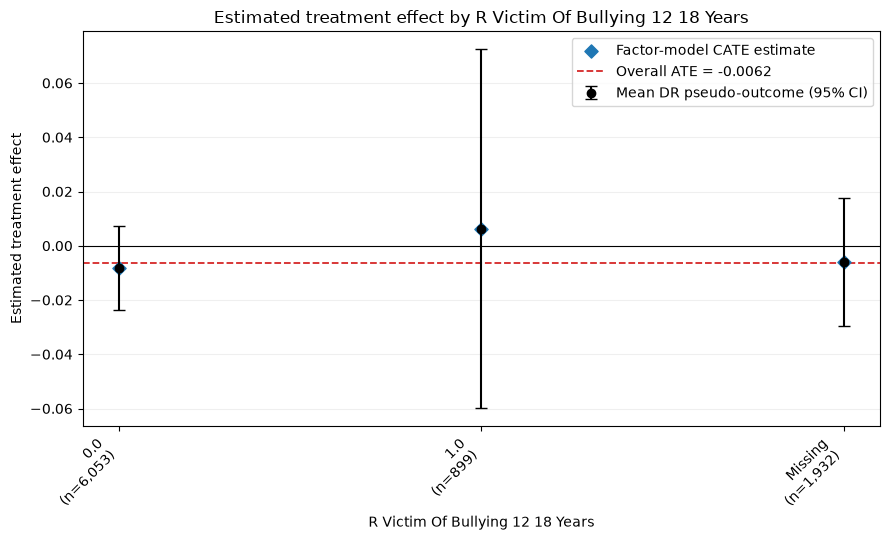

earliest_arrest_before_18
Apparent factor-model pseudo-R²: 0.00010


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,0,7310,-0.00320,0.65116,-0.00320,0.00762,-0.01813,0.01173
1,1,1574,-0.02034,0.63523,-0.02034,0.01601,-0.05173,0.01104


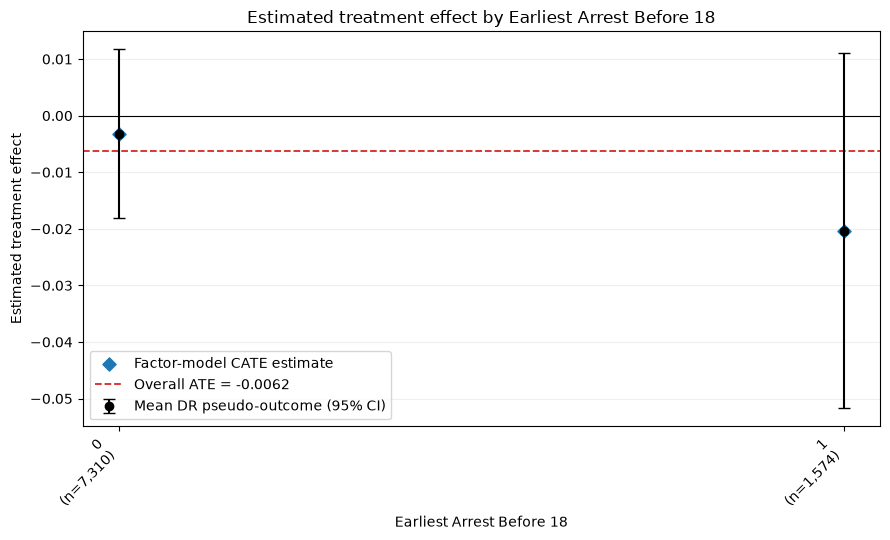

sex
Apparent factor-model pseudo-R²: 0.00044


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,1,4554,-0.01953,0.66450,-0.01953,0.00985,-0.03883,-0.00023
1,2,4330,0.00774,0.63072,0.00774,0.00959,-0.01105,0.02653


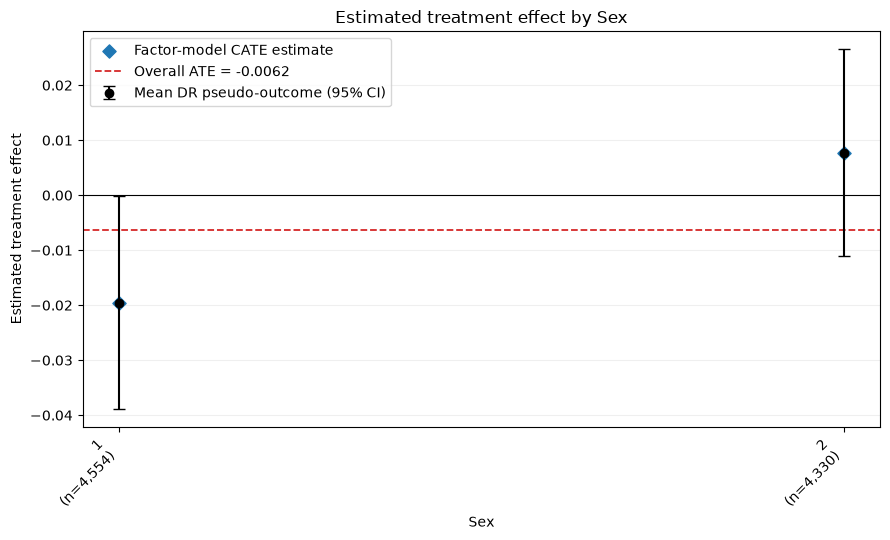

r_ever_live_through_hard_times
Apparent factor-model pseudo-R²: 0.00001


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,0.0,7370,-0.00659,0.66205,-0.00659,0.00771,-0.02171,0.00852
1,1.0,430,0.00462,0.81471,0.00462,0.03929,-0.07238,0.08163
2,Missing,1084,-0.00814,0.45024,-0.00814,0.01368,-0.03495,0.01866


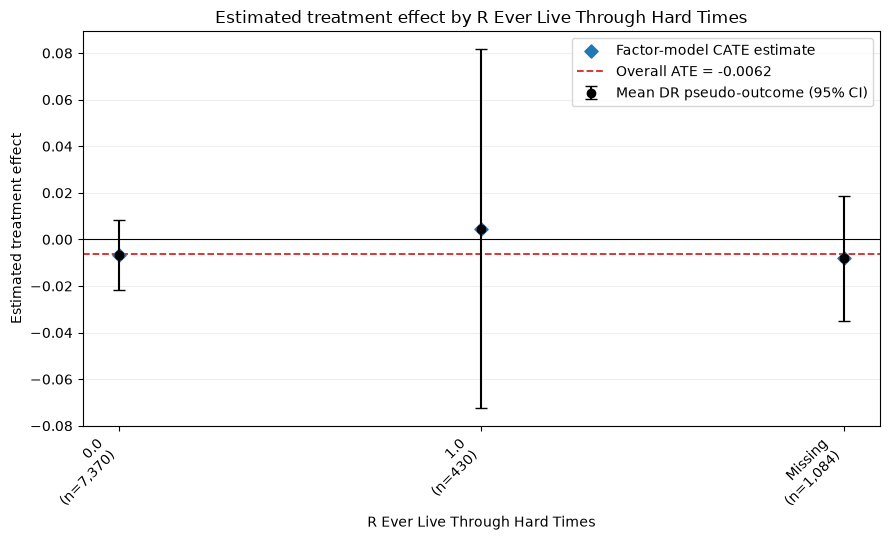

race_ethnicity
Apparent factor-model pseudo-R²: 0.00038


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,Asian,156,-0.00315,0.27538,-0.00315,0.02205,-0.04636,0.04006
1,Black,2317,0.00281,0.56667,0.00281,0.01177,-0.02027,0.02588
2,Hispanic,1884,-0.02882,0.70116,-0.02882,0.01615,-0.06048,0.00284
3,Other,180,0.02727,0.55042,0.02727,0.04103,-0.05314,0.10768
4,White,4347,-0.00277,0.67793,-0.00277,0.01028,-0.02293,0.01738


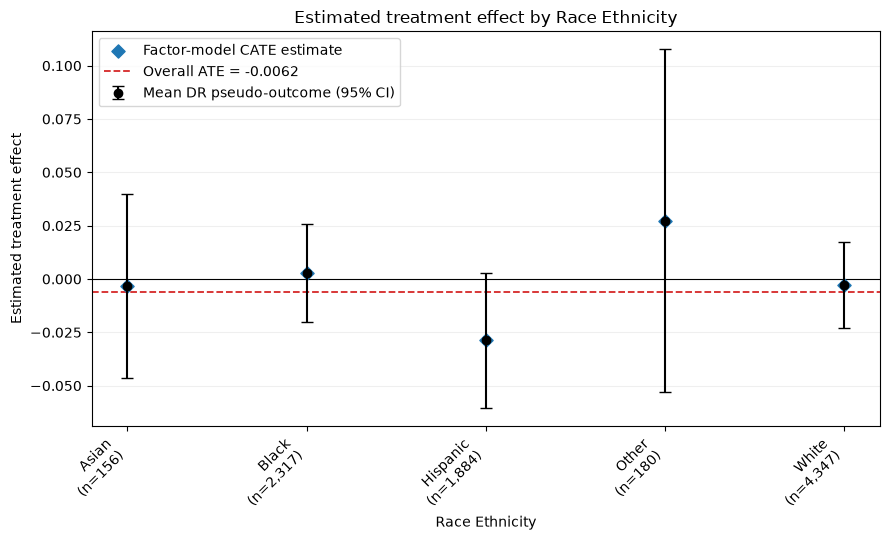

mother_serve_prison_sentence
Apparent factor-model pseudo-R²: 0.00066


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,0.0,6970,0.00250,0.61945,0.00250,0.00742,-0.01204,0.01704
1,1.0,94,-0.04825,0.33312,-0.04825,0.03436,-0.11559,0.01910
2,Missing,1820,-0.03754,0.75877,-0.03754,0.01779,-0.07240,-0.00268


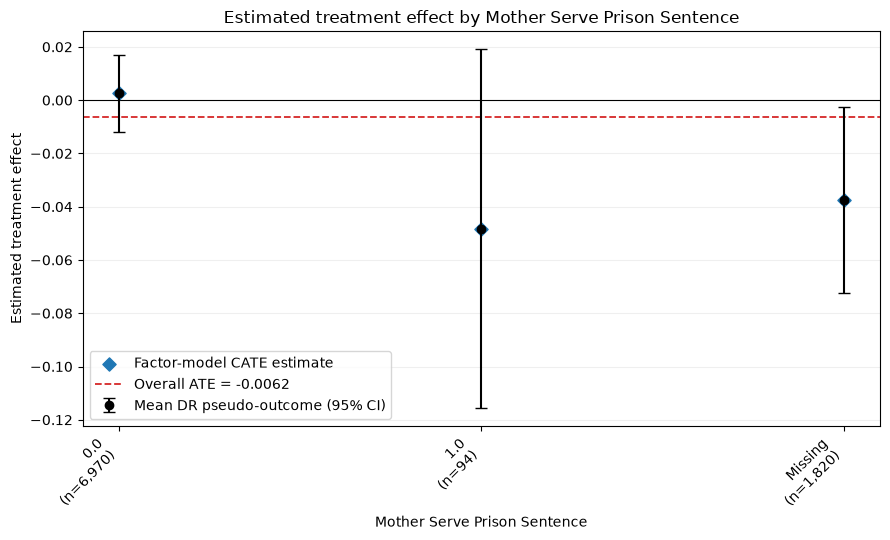

father_serve_prison_sentence
Apparent factor-model pseudo-R²: 0.00015


,category,n,observed_DR_mean,observed_DR_sd,factor_CATE,observed_DR_se,ci_lower,ci_upper
0,0.0,6072,-0.00246,0.60707,-0.00246,0.00779,-0.01773,0.01281
1,1.0,430,0.00956,0.66324,0.00956,0.03198,-0.05313,0.07225
2,Missing,2382,-0.01872,0.74106,-0.01872,0.01518,-0.04848,0.01104


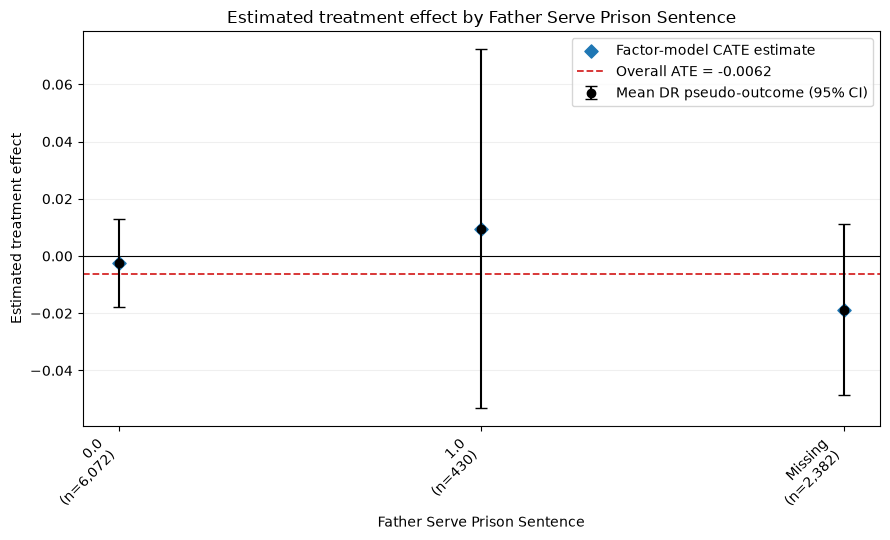

In [38]:
# ============================================================
# CATEGORICAL AND ORDINAL CATE PLOTS
# ============================================================

def categorical_plot_table(variable):
    categories = (
        analysis[variable]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

    work = pd.DataFrame({
        "category": categories,
        "dr_primary": analysis[
            "dr_primary"
        ].to_numpy(dtype=float),
        "factor_prediction": (
            categorical_results[variable][
                "mean_prediction"
            ]
        ),
    })

    table = (
        work
        .groupby(
            "category",
            observed=True,
        )
        .agg(
            n=("dr_primary", "size"),
            observed_DR_mean=(
                "dr_primary",
                "mean",
            ),
            observed_DR_sd=(
                "dr_primary",
                "std",
            ),
            factor_CATE=(
                "factor_prediction",
                "mean",
            ),
        )
        .reset_index()
    )

    # Standard error and 95% CI for each group's
    # mean DR pseudo-outcome.
    table["observed_DR_se"] = (
        table["observed_DR_sd"]
        / np.sqrt(table["n"])
    )

    table["ci_lower"] = (
        table["observed_DR_mean"]
        - 1.96 * table["observed_DR_se"]
    )

    table["ci_upper"] = (
        table["observed_DR_mean"]
        + 1.96 * table["observed_DR_se"]
    )

    # Sort numeric-coded categories numerically when possible,
    # while placing missing values last.
    def category_sort_key(value):
        if value == "Missing":
            return (2, 0)

        try:
            return (0, float(value))
        except ValueError:
            return (1, value.lower())

    category_order = sorted(
        table["category"],
        key=category_sort_key,
    )

    table["category"] = pd.Categorical(
        table["category"],
        categories=category_order,
        ordered=True,
    )

    table = (
        table
        .sort_values("category")
        .reset_index(drop=True)
    )

    return table


def plot_categorical_cate(variable):
    table = categorical_plot_table(
        variable
    )

    x_positions = np.arange(
        len(table)
    )

    figure_width = max(
        9,
        0.75 * len(table),
    )

    fig, ax = plt.subplots(
        figsize=(figure_width, 5.5)
    )

    # Observed grouped means and their 95% CIs.
    ax.errorbar(
        x_positions,
        table["observed_DR_mean"],
        yerr=[
            (
                table["observed_DR_mean"]
                - table["ci_lower"]
            ),
            (
                table["ci_upper"]
                - table["observed_DR_mean"]
            ),
        ],
        fmt="o",
        color="black",
        capsize=4,
        markersize=6,
        label=(
            "Mean DR pseudo-outcome "
            "(95% CI)"
        ),
        zorder=4,
    )

    # Estimated CATE from the categorical factor model.
    ax.scatter(
        x_positions,
        table["factor_CATE"],
        marker="D",
        color="tab:blue",
        s=45,
        label="Factor-model CATE estimate",
        zorder=3,
    )

    # No-effect reference.
    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    # Overall ATE benchmark.
    ax.axhline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
        label=(
            f"Overall ATE = "
            f"{OVERALL_ATE:.4f}"
        ),
    )

    readable_name = (
        variable
        .replace("_", " ")
        .title()
    )

    ax.set_title(
        f"Estimated treatment effect by "
        f"{readable_name}"
    )

    ax.set_xlabel(readable_name)

    ax.set_ylabel(
        "Estimated treatment effect"
    )

    ax.set_xticks(x_positions)

    ax.set_xticklabels(
        [
            f"{category}\n(n={n:,})"
            for category, n in zip(
                table["category"].astype(str),
                table["n"],
            )
        ],
        rotation=45,
        ha="right",
    )

    ax.legend()
    ax.grid(
        axis="y",
        alpha=0.20,
    )

    plt.tight_layout()
    plt.show()


# Create one plot for every ordinal and categorical variable.
for variable in all_categorical_features:
    row = categorical_model_comparison.loc[
        categorical_model_comparison[
            "variable"
        ] == variable
    ].iloc[0]

    print("=" * 80)
    print(variable)

    print(
        "Apparent factor-model pseudo-R²: "
        f"{row['apparent_pseudo_R2']:.5f}"
    )

    display(
        categorical_plot_table(variable)
        .round(5)
    )

    plot_categorical_cate(variable)

In [34]:
X_rf = analysis[
    all_features
].copy()

for variable in all_categorical_features:
    X_rf[variable] = (
        X_rf[variable]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )


rf_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            (
                "impute",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                ),
            ),
        ]),
        numeric_features,
    ),
    (
        "categorical",
        Pipeline([
            (
                "one_hot",
                OneHotEncoder(
                    handle_unknown=(
                        "infrequent_if_exist"
                    ),
                    min_frequency=20,
                ),
            ),
        ]),
        all_categorical_features,
    ),
])

rf_model = Pipeline([
    (
        "preprocessor",
        rf_preprocessor,
    ),
    (
        "forest",
        RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=100,
            max_features=0.70,
            random_state=2026,
            n_jobs=-1,
        ),
    ),
])

rf_target = analysis[
    "dr_primary"
].to_numpy(dtype=float)

rf_model.fit(
    X_rf,
    rf_target,
)

rf_prediction = rf_model.predict(
    X_rf
)

analysis["cate_rf_all"] = (
    rf_prediction
)

rf_model_mse = mean_squared_error(
    rf_target,
    rf_prediction,
)

rf_baseline_prediction = np.repeat(
    OVERALL_ATE,
    len(analysis),
)

rf_baseline_mse = mean_squared_error(
    rf_target,
    rf_baseline_prediction,
)

rf_apparent_pseudo_r2 = (
    1
    - rf_model_mse
    / rf_baseline_mse
)

rf_performance = pd.DataFrame([{
    "model": ACTIVE_MODEL,
    "RF_MSE": rf_model_mse,
    "baseline_MSE": rf_baseline_mse,
    "apparent_pseudo_R2": (
        rf_apparent_pseudo_r2
    ),
}])

display(
    rf_performance.round(6)
)

print(
    "This RF pseudo-R² is apparent/in-sample."
)


# ============================================================
# PERMUTATION IMPORTANCE ON THE FITTED SAMPLE
# ============================================================

importance_rows = []

for variable_position, variable in enumerate(
    all_features
):
    print(f"Permuting: {variable}")

    for permutation in range(
        N_PERMUTATIONS
    ):
        X_permuted = X_rf.copy()

        rng = np.random.default_rng(
            2026
            + variable_position * 1_000
            + permutation
        )

        X_permuted[variable] = (
            rng.permutation(
                X_permuted[
                    variable
                ].to_numpy()
            )
        )

        permuted_prediction = (
            rf_model.predict(
                X_permuted
            )
        )

        permuted_mse = mean_squared_error(
            rf_target,
            permuted_prediction,
        )

        importance_rows.append({
            "variable": variable,
            "permutation": permutation,
            "importance": (
                permuted_mse
                - rf_model_mse
            ),
        })

importance_raw = pd.DataFrame(
    importance_rows
)

importance_summary = (
    importance_raw
    .groupby("variable")["importance"]
    .agg(
        mean_importance="mean",
        sd_importance="std",
        median_importance="median",
        proportion_positive=lambda x:
            (x > 0).mean(),
    )
    .reset_index()
    .sort_values(
        "mean_importance",
        ascending=False,
    )
)

display(
    importance_summary.round(7)
)

,model,RF_MSE,baseline_MSE,apparent_pseudo_R2
0,xgboost,0.408851,0.420331,0.027311


This RF pseudo-R² is apparent/in-sample.
Permuting: total_number_of_incarcerations
Permuting: days_r_absent_from_school
Permuting: r_threatened_to_be_hurt_at_school
Permuting: r_in_a_fight_at_school
Permuting: household_net_worth
Permuting: household_size
Permuting: asvab_math_verbal_score_percent
Permuting: teachers_good
Permuting: discipline_is_fair_agree_disagree
Permuting: percent_of_peers_who_smoke
Permuting: percent_of_peers_who_get_drunk_1_times_a_month
Permuting: percent_of_peers_belong_to_a_gang
Permuting: percent_of_peers_who_have_had_sex
Permuting: biological_father_education
Permuting: biological_mother_education
Permuting: bullying_victim_before_age_12
Permuting: r_victim_of_bullying_12_18_years
Permuting: earliest_arrest_before_18
Permuting: sex
Permuting: r_ever_live_through_hard_times
Permuting: race_ethnicity
Permuting: mother_serve_prison_sentence
Permuting: father_serve_prison_sentence


,variable,mean_importance,sd_importance,median_importance,proportion_positive
8,household_net_worth,0.003956,0.000280,0.004025,1.0
0,asvab_math_verbal_score_percent,0.003417,0.000220,0.003479,1.0
4,days_r_absent_from_school,0.002979,0.000236,0.003020,1.0
14,percent_of_peers_who_smoke,0.001557,0.000108,0.001547,1.0
9,household_size,0.001534,0.000120,0.001538,1.0
10,mother_serve_prison_sentence,0.001508,0.000164,0.001540,1.0
2,biological_mother_education,0.001501,0.000159,0.001520,1.0
5,discipline_is_fair_agree_disagree,0.001312,0.000164,0.001312,1.0
20,sex,0.001287,0.000158,0.001290,1.0
19,race_ethnicity,0.001167,0.000120,0.001154,1.0


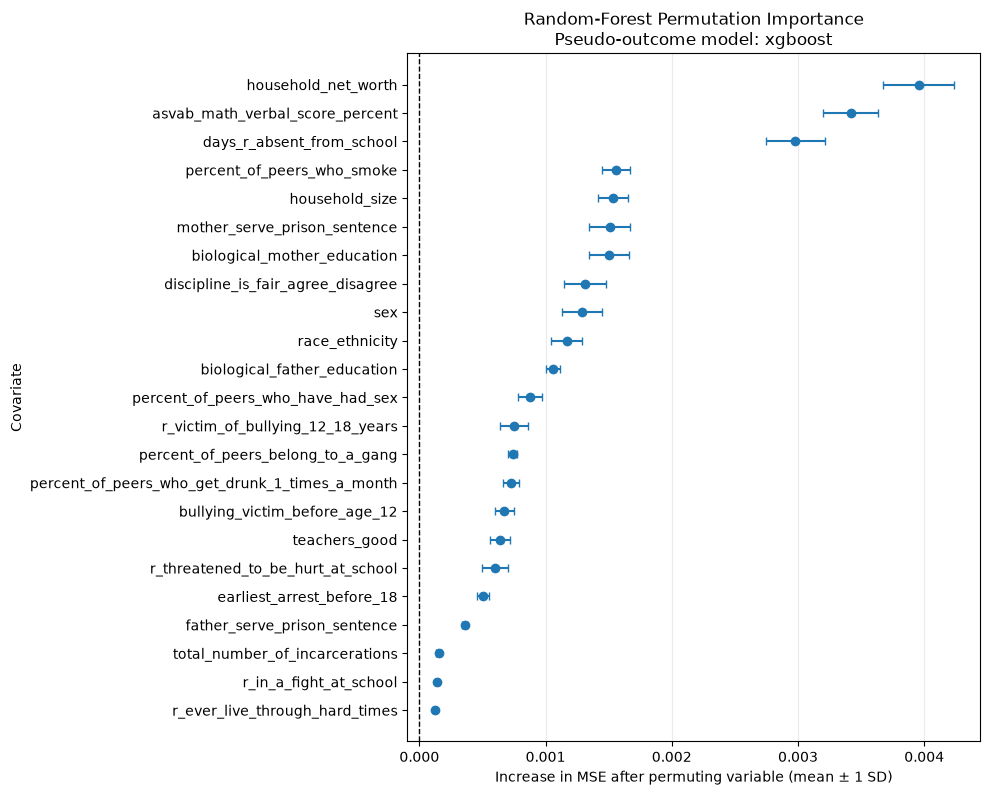

In [35]:
# ============================================================
# RANDOM-FOREST PERMUTATION IMPORTANCE PLOT
# ============================================================

importance_plot = (
    importance_summary
    .sort_values(
        "mean_importance",
        ascending=True,
    )
    .copy()
)

fig_height = max(
    6,
    0.35 * len(importance_plot),
)

fig, ax = plt.subplots(
    figsize=(10, fig_height)
)

ax.errorbar(
    importance_plot["mean_importance"],
    importance_plot["variable"],
    xerr=importance_plot["sd_importance"],
    fmt="o",
    color="tab:blue",
    ecolor="tab:blue",
    elinewidth=1.5,
    capsize=3,
    markersize=6,
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

ax.set_title(
    f"Random-Forest Permutation Importance\n"
    f"Pseudo-outcome model: {ACTIVE_MODEL}"
)

ax.set_xlabel(
    "Increase in MSE after permuting variable "
    "(mean ± 1 SD)"
)

ax.set_ylabel("Covariate")

ax.grid(
    axis="x",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

In [36]:
def calibration_table(
    prediction,
    observed_score,
    number_of_groups=5,
):
    work = pd.DataFrame({
        "prediction": prediction,
        "observed_score": observed_score,
    })

    work["prediction_rank"] = (
        work["prediction"]
        .rank(method="first")
    )

    work["CATE_group"] = pd.qcut(
        work["prediction_rank"],
        q=number_of_groups,
        labels=[
            f"Q{index}"
            for index in range(
                1,
                number_of_groups + 1
            )
        ],
    )

    table = (
        work
        .groupby(
            "CATE_group",
            observed=True,
        )
        .agg(
            n=("observed_score", "size"),
            mean_predicted_CATE=(
                "prediction",
                "mean",
            ),
            mean_DR_score=(
                "observed_score",
                "mean",
            ),
            sd_DR_score=(
                "observed_score",
                "std",
            ),
        )
        .reset_index()
    )

    table["se_DR_mean"] = (
        table["sd_DR_score"]
        / np.sqrt(table["n"])
    )

    table["ci_lower"] = (
        table["mean_DR_score"]
        - 1.96 * table["se_DR_mean"]
    )

    table["ci_upper"] = (
        table["mean_DR_score"]
        + 1.96 * table["se_DR_mean"]
    )

    return table


rf_calibration = calibration_table(
    prediction=analysis[
        "cate_rf_all"
    ],
    observed_score=analysis[
        "dr_primary"
    ],
)

display(
    rf_calibration.round(6)
)

print(
    "This is apparent/in-sample calibration."
)

,CATE_group,n,mean_predicted_CATE,mean_DR_score,sd_DR_score,se_DR_mean,ci_lower,ci_upper
0,Q1,1777,-0.058185,-0.217500,1.042469,0.024730,-0.265971,-0.169030
1,Q2,1777,-0.023409,-0.047789,0.362360,0.008596,-0.064637,-0.030941
2,Q3,1776,-0.004218,-0.014744,0.294781,0.006995,-0.028454,-0.001034
3,Q4,1777,0.014297,0.037702,0.324351,0.007694,0.022621,0.052782
4,Q5,1777,0.041768,0.211138,0.772552,0.018327,0.175218,0.247058


This is apparent/in-sample calibration.


In [37]:
if SAVE_OUTPUTS:
    safe_model_name = (
        ACTIVE_MODEL
        .replace(" ", "_")
        .lower()
    )

    numeric_model_comparison.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "numeric_comparison.csv"
        ),
        index=False,
    )

    categorical_model_comparison.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "categorical_comparison.csv"
        ),
        index=False,
    )

    rf_performance.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "rf_performance.csv"
        ),
        index=False,
    )

    importance_summary.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "rf_importance.csv"
        ),
        index=False,
    )

    rf_calibration.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "rf_calibration.csv"
        ),
        index=False,
    )

    respondent_output = analysis[
        [
            ID_COL,
            "model",
            "Z",
            "R",
            "mu1_minus_mu0",
            "phi_i",
            "dr_primary",
        ]
    ].copy()

    for variable in numeric_features:
        respondent_output[
            f"linear_{variable}"
        ] = numeric_results[
            variable
        ]["linear"]["mean_prediction"]

        respondent_output[
            f"spline_{variable}"
        ] = numeric_results[
            variable
        ]["spline"]["mean_prediction"]

    for variable in all_categorical_features:
        respondent_output[
            f"factor_{variable}"
        ] = categorical_results[
            variable
        ]["mean_prediction"]

    respondent_output[
        "cate_rf_all"
    ] = analysis[
        "cate_rf_all"
    ]

    respondent_output.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "respondent_estimates.csv"
        ),
        index=False,
    )

    print(
        f"Saved outputs for model: "
        f"{ACTIVE_MODEL}"
    )

Saved outputs for model: xgboost
